<a href="https://colab.research.google.com/github/ivannarch865/ivannarichards5to/blob/main/A9_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
file_path_antro= 'https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/antropometria-dataset.csv'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn import linear_model
import seaborn as sns

df_antro=pd.read_csv(file_path_antro)
df_antro.head()

,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,PrimaryLast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


In [77]:
df_antro.columns

Index(['folio', 'intp', 'entidad', 'desc_ent', 'sexo', 'edad', 'meses', 'peso',
       'ropa', 'talla', 'emb', 'temb', 'cintura', 'cadera', 'sistol',
       'diastol', 'hpresion', 'tbrazo', 'htension', 'PrimaryLast', 'code_upm',
       'est_dis', 'est_urb', 'est_marg', 'pondef', 'est_var'],
      dtype='object')

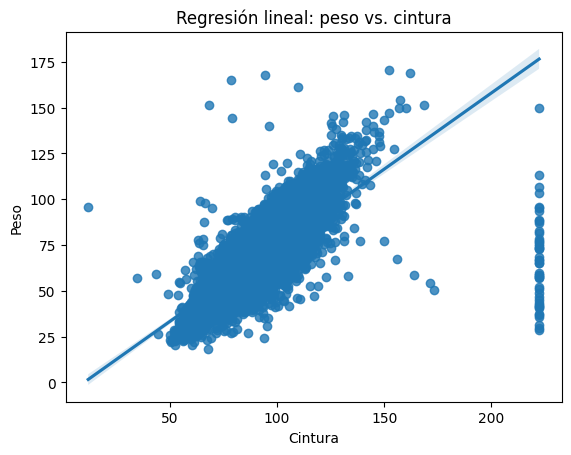

In [7]:
sns.regplot(data=df_antro, x='cintura', y='peso')

plt.xlabel('Cintura')
plt.ylabel('Peso')
plt.title('Regresión lineal: peso vs. cintura')
plt.show()

In [17]:
from sklearn import linear_model

favs = ['peso', 'cintura']
ndf = df_antro[favs].dropna()

X = pd.DataFrame(ndf['cintura'])
y = ndf['peso']



In [27]:
reg_eqn= 'peso ~ cintura'
B0 = modelA.params['Intercept']
B1 = modelA.params['cintura']


modelA.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                 3.028e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:01:53   Log-Likelihood:                -68622.
No. Observations:               18032   AIC:                         1.372e+05
Df Residuals:                   18030   BIC:                         1.373e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -8.3137      0.427    -19.458      0.000      -9.151      -7.476
cintura        0.8316      0.005    173.999      0.000       0.822       0.841
==============================================================================
Omnibus:                    12737.948   Durbin-Watson:                   1.884
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          1022852.813
Skew:                          -2.683   Prob(JB):                         0.00
Kurtosis:                      39.505   Cond. No.                         472.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [22]:
modelA.params

,0
Intercept,-8.313656
cintura,0.831568


In [12]:
modelA.resid

,0
0,-0.062068
1,-9.256672
2,6.899685
3,-8.679342
4,12.296515
...,...
18635,6.777867
18636,-7.979387
18637,-4.268694
18638,-15.751528


In [13]:
modelA.fittedvalues

,0
0,73.762068
1,44.906672
2,47.900315
3,42.079342
4,85.653485
...,...
18635,69.022133
18636,77.379387
18637,51.018694
18638,74.801528


In [23]:
study = [
    ndf['peso'],
    ndf['cintura'],
    modelA.fittedvalues,
    modelA.resid
]

study_table = pd.concat(study, axis=1)

study_table.columns = [
    'peso',
    'cintura',
    'Predicted_weight',
    'Residual'
]

study_table

,peso,cintura,Predicted_weight,Residual
0,73.70,98.70,73.762068,-0.062068
1,35.65,64.00,44.906672,-9.256672
2,54.80,67.60,47.900315,6.899685
3,33.40,60.60,42.079342,-8.679342
4,97.95,113.00,85.653485,12.296515
...,...,...,...,...
18635,75.80,93.00,69.022133,6.777867
18636,69.40,103.05,77.379387,-7.979387
18637,46.75,71.35,51.018694,-4.268694
18638,59.05,99.95,74.801528,-15.751528


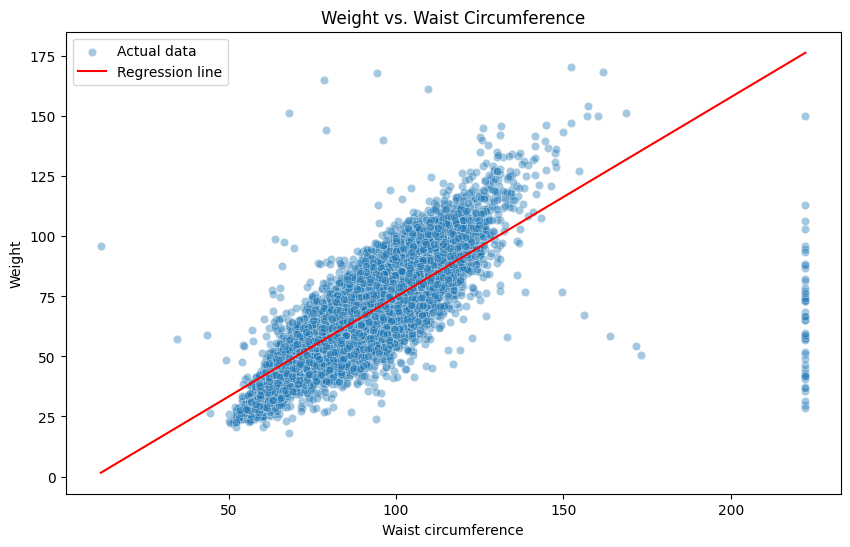

In [24]:
ordered_table = study_table.sort_values(by='cintura')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=study_table,
    x='cintura',
    y='peso',
    alpha=0.4,
    label='Actual data'
)

plt.plot(
    ordered_table['cintura'],
    ordered_table['Predicted_weight'],
    color='red',
    label='Regression line'
)

plt.xlabel('Waist circumference')
plt.ylabel('Weight')
plt.title('Weight vs. Waist Circumference')
plt.legend()
plt.show()

#Analisis For Sex 1

In [25]:
men = df_antro.loc[
    df_antro['sexo'] == 1, ['peso', 'cintura']
].dropna()

model_men = sm.OLS.from_formula('peso ~ cintura', data=men).fit()

model_men.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                 2.022e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:01:18   Log-Likelihood:                -30486.
No. Observations:                8154   AIC:                         6.098e+04
Df Residuals:                    8152   BIC:                         6.099e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -16.5015      0.599    -27.556      0.000     -17.675     -15.328
cintura        0.9558      0.007    142.200      0.000       0.943       0.969
==============================================================================
Omnibus:                     6572.799   Durbin-Watson:                   1.889
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           878711.348
Skew:                          -3.142   Prob(JB):                         0.00
Kurtosis:                      53.466   Cond. No.                         474.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [28]:
B0_men = model_men.params['Intercept']
B1_men = model_men.params['cintura']
model_men.params

,0
Intercept,-16.501455
cintura,0.955774


In [31]:
model_men.resid

,0
3,-8.018430
5,-8.467079
9,-11.600918
17,-10.014007
21,-15.593972
...,...
18626,-5.787951
18627,-11.192743
18630,-6.351224
18634,9.189330


In [39]:
model_men.fittedvalues

,0
3,41.418430
5,40.367079
9,59.625918
17,41.514007
21,75.443972
...,...
18626,83.137951
18627,79.792743
18630,63.401224
18634,109.660670


In [32]:
study_men = [
    men['peso'],
    men['cintura'],
    model_men.fittedvalues,
    model_men.resid
]

table_men = pd.concat(study_men, axis=1)

table_men.columns = [
    'peso', 'cintura', 'Predicted_weight', 'Residual'
]

table_men

,peso,cintura,Predicted_weight,Residual
3,33.400,60.60,41.418430,-8.018430
5,31.900,59.50,40.367079,-8.467079
9,48.025,79.65,59.625918,-11.600918
17,31.500,60.70,41.514007,-10.014007
21,59.850,96.20,75.443972,-15.593972
...,...,...,...,...
18626,77.350,104.25,83.137951,-5.787951
18627,68.600,100.75,79.792743,-11.192743
18630,57.050,83.60,63.401224,-6.351224
18634,118.850,132.00,109.660670,9.189330


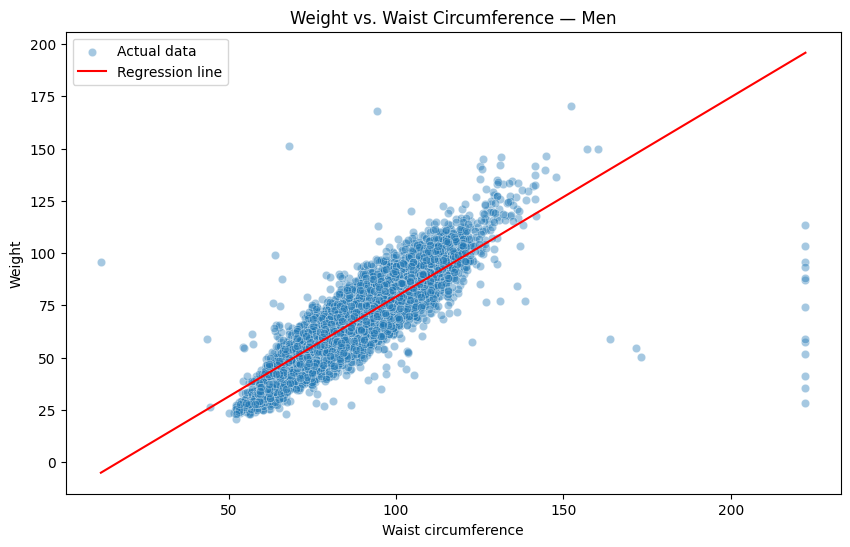

In [33]:
ordered_men = table_men.sort_values(by='cintura')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=table_men,
    x='cintura',
    y='peso',
    alpha=0.4,
    label='Actual data'
)

plt.plot(
    ordered_men['cintura'],
    ordered_men['Predicted_weight'],
    color='red',
    label='Regression line'
)

plt.xlabel('Waist circumference')
plt.ylabel('Weight')
plt.title('Weight vs. Waist Circumference — Men')
plt.legend()
plt.show()

#Analisis For Sex 2

In [36]:
women = df_antro.loc[
    df_antro['sexo'] == 2, ['peso', 'cintura']
].dropna()

model_women = sm.OLS.from_formula('peso ~ cintura', data=women).fit()

model_women.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.583
Model:                            OLS   Adj. R-squared:                  0.583
Method:                 Least Squares   F-statistic:                 1.381e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:05:01   Log-Likelihood:                -37386.
No. Observations:                9878   AIC:                         7.478e+04
Df Residuals:                    9876   BIC:                         7.479e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.1852      0.562     -3.887      0.000      -3.287      -1.083
cintura        0.7368      0.006    117.510      0.000       0.724       0.749
==============================================================================
Omnibus:                     6504.425   Durbin-Watson:                   1.913
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           441820.169
Skew:                          -2.437   Prob(JB):                         0.00
Kurtosis:                      35.399   Cond. No.                         470.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [37]:
B0_women = model_women.params['Intercept']
B1_women = model_women.params['cintura']
model_women.params

,0
Intercept,-2.185157
cintura,0.736788


In [38]:
model_women.resid

,0
0,3.164197
1,-9.319265
2,7.178299
4,16.878131
6,-8.082786
...,...
18633,8.253421
18635,9.463888
18636,-4.340830
18638,-12.406788


In [40]:
model_women.fittedvalues

,0
0,70.535803
1,44.969265
2,47.621701
4,81.071869
6,40.032786
...,...
18633,67.146579
18635,66.336112
18636,73.740830
18638,71.456788


In [41]:
study_women = [
    women['peso'],
    women['cintura'],
    model_women.fittedvalues,
    model_women.resid
]

table_women = pd.concat(study_women, axis=1)

table_women.columns = [
    'peso', 'cintura', 'Predicted_weight', 'Residual'
]

table_women

,peso,cintura,Predicted_weight,Residual
0,73.70,98.70,70.535803,3.164197
1,35.65,64.00,44.969265,-9.319265
2,54.80,67.60,47.621701,7.178299
4,97.95,113.00,81.071869,16.878131
6,31.95,57.30,40.032786,-8.082786
...,...,...,...,...
18633,75.40,94.10,67.146579,8.253421
18635,75.80,93.00,66.336112,9.463888
18636,69.40,103.05,73.740830,-4.340830
18638,59.05,99.95,71.456788,-12.406788


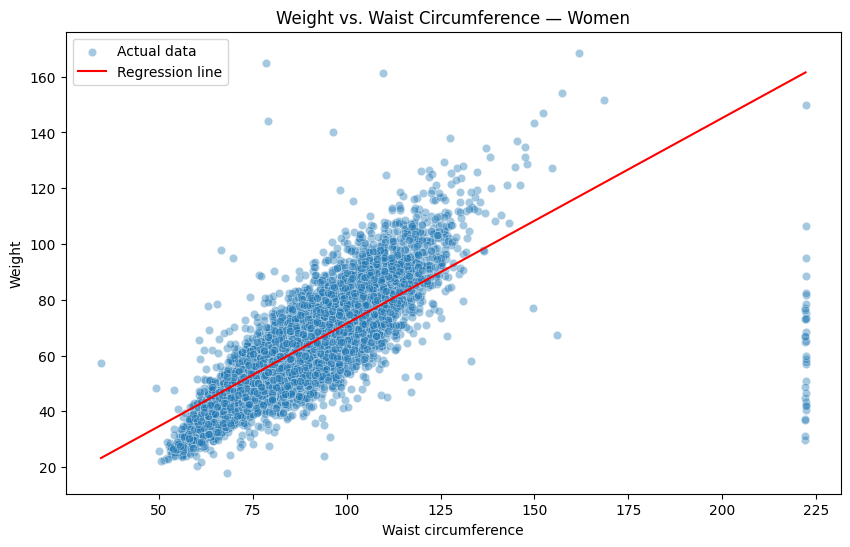

In [42]:
ordered_women = table_women.sort_values(by='cintura')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=table_women,
    x='cintura',
    y='peso',
    alpha=0.4,
    label='Actual data'
)

plt.plot(
    ordered_women['cintura'],
    ordered_women['Predicted_weight'],
    color='red',
    label='Regression line'
)

plt.xlabel('Waist circumference')
plt.ylabel('Weight')
plt.title('Weight vs. Waist Circumference — Women')
plt.legend()
plt.show()

#1. R-squared of the model

In [69]:
favs = ['cadera', 'peso']
ndf = df_antro[favs].dropna()

X = pd.DataFrame(ndf['peso'])
y = ndf['cadera']

In [71]:
reg_eqn= 'cadera ~ peso'
modele=sm.OLS.from_formula(reg_eqn, data=ndf).fit()

modele.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 cadera   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                 2.748e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:38:45   Log-Likelihood:                -65165.
No. Observations:               18032   AIC:                         1.303e+05
Df Residuals:                   18030   BIC:                         1.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.4600      0.252    228.032      0.000      56.966      57.954
peso           0.6227      0.004    165.771      0.000       0.615       0.630
==============================================================================
Omnibus:                    22321.754   Durbin-Watson:                   2.002
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          6875856.023
Skew:                           6.463   Prob(JB):                         0.00
Kurtosis:                      97.786   Cond. No.                         253.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [73]:
print('R-squared:', modele.rsquared)

R-squared: 0.6038232783357169


#2. Coefficient Correlation Weight and Age

In [74]:
print('Correlation coefficient:', df_antro['peso'].corr(df_antro['edad']))

Correlation coefficient: 0.3170495816571554


#3. Durbin-Watson Diastol


In [82]:
favs = ['diastol', 'sistol']
ndf = df_antro[favs].dropna()


In [85]:
reg_eqn= 'diastol ~ sistol'
modelC=sm.OLS.from_formula(reg_eqn, data=ndf).fit()

modelC.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                diastol   R-squared:                       0.441
Model:                            OLS   Adj. R-squared:                  0.441
Method:                 Least Squares   F-statistic:                 1.469e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        01:05:47   Log-Likelihood:                -66351.
No. Observations:               18640   AIC:                         1.327e+05
Df Residuals:                   18638   BIC:                         1.327e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.6843      0.432     54.811      0.000      22.837      24.531
sistol         0.4375      0.004    121.220      0.000       0.430       0.445
==============================================================================
Omnibus:                     1040.446   Durbin-Watson:                   1.746
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4079.429
Skew:                           0.118   Prob(JB):                         0.00
Kurtosis:                       5.280   Cond. No.                         830.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [86]:
from statsmodels.stats.stattools import durbin_watson

print('Durbin-Watson:', durbin_watson(modelC.resid))

Durbin-Watson: 1.7463985152850534


#4. Regression Diastol

In [58]:
model_multiple = sm.OLS.from_formula(
    'diastol ~ sistol + edad + peso + cintura',
    data=df_antro
).fit()

print('b4:', model_multiple.params['cintura'])

b4: 0.02016675116144312


#5. Regression Hip

In [59]:
favs = ['peso', 'cadera']
ndf = df_antro[favs].dropna()

X = pd.DataFrame(ndf['peso'])
y = ndf['cadera']

In [60]:
reg_eqn= 'cadera ~ peso'
modelC=sm.OLS.from_formula(reg_eqn, data=ndf).fit()

modelC.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 cadera   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                 2.748e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:31:19   Log-Likelihood:                -65165.
No. Observations:               18032   AIC:                         1.303e+05
Df Residuals:                   18030   BIC:                         1.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.4600      0.252    228.032      0.000      56.966      57.954
peso           0.6227      0.004    165.771      0.000       0.615       0.630
==============================================================================
Omnibus:                    22321.754   Durbin-Watson:                   2.002
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          6875856.023
Skew:                           6.463   Prob(JB):                         0.00
Kurtosis:                      97.786   Cond. No.                         253.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [62]:
residuals= modelC.resid

In [67]:


print('Median of residuals:', residuals.median())

Median of residuals: -0.6495739811776744
